# Cvičenie II - Lineárne modely a predikcia časových radov

## Predikcia s ARIMA modelmi

Modely Arima predstavujú široko používanú skupinu modelov na analýzu a predikciu stacionárnych časových radov.

### Lag v autokorelácii
Lag vyjadruje o koľko časových krokov porovnávame aktuálnu hodnotu s hodnotou z minulosti.

Napríklad:
- **lag 1**: porovnávame ($Y{_t}$) s ($Y_{t-1}$)
- **lag 2**: porovnávame ($Y{_t}$) s ($Y_{t-2}$)
- **lag 12**: aktuálnu hodnotu porovnávame s hodnotou spred 12 období

S lagmi sa stretávame pri autokorelácii, pretože autokorelácia meria, ako silno súvisí časový rad so svojimi vlastnými minulými hodnotami pri rôznych lagoch.

To nám pomáha odhaliť napríklad:

- krátkodobú závislosť medzi susednými pozorovaniami,
- opakujúce sa sezónne vzory,
- či minulé hodnoty obsahujú informáciu užitočnú pre predikciu.

---

#### Rozdiel medzi ACF a PACF: Celková vs. priama závislosť

<div align="center">
<img src="images/acf_vs_pacf.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>

## ARIMA model

ARIMA kombinuje tri zložky – autoregresiu, diferencovanie a moving-average zložku.

### AR(p) – Autoregresná zložka

Autoregresná zložka modeluje vzťah medzi aktuálnym pozorovaním a jeho vlastnými minulými hodnotami:

$$X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \varepsilon_t$$


Parameter \(p\) určuje, koľko minulých hodnôt priamo vstupuje do modelu.

### I(d) – Integrovaná zložka

Parameter \(d\) vyjadruje, koľkokrát časový rad diferencujeme, aby sme získali približne stacionárny rad.

Ak prvá diferencia vytvorí stacionárny rad, potom \(d=1\).

### MA(q) – Moving-average

MA zložka modeluje vzťah medzi aktuálnym pozorovaním a minulými náhodnými šokmi:

$$X_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q}$$

Parameter \(q\) určuje počet minulých inovácií, ktoré vstupujú do modelu.

--------
## 1. Príprava dát

Total observations: 440; frequency: MS
Training: 352 (80%), 1980-01 to 2009-04
Testing: 88 (20%), 2009-05 to 2016-08


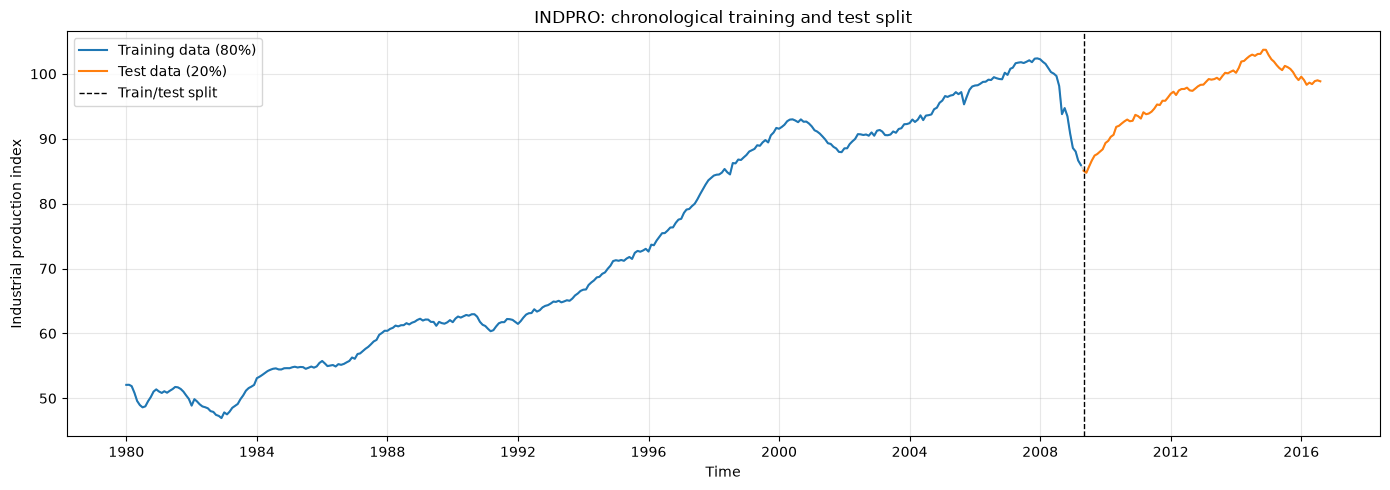

In [8]:
# TODO:
# 1. Načítajte INDPRO.csv.
# 2. Rozdeľte dáta v pomere 80/20 na trénovanie a testovanie - chronologicky.
# 3. Vykreslite dataset na grafe.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Support running from either the notebook folder or the workspace root.
data_path = Path("data/INDPRO.csv")
if not data_path.is_file():
    data_path = Path("02_exercises") / data_path

data_indpro = pd.read_csv(
    data_path, parse_dates=["observation_date"], index_col="observation_date"
).sort_index()
indpro = data_indpro["INDPRO"].asfreq("MS")
if indpro.isna().any():
    raise ValueError("Handle missing monthly observations before splitting.")

# Keep the first 80% for training and the last 20% for testing.
# Do not shuffle: future observations must not enter the training set.
split_index = int(len(indpro) * 0.8)
train = indpro.iloc[:split_index].copy()
test = indpro.iloc[split_index:].copy()

print(f"Total observations: {len(indpro)}; frequency: {pd.infer_freq(indpro.index)}")
print(f"Training: {len(train)} ({len(train) / len(indpro):.0%}), "
      f"{train.index.min():%Y-%m} to {train.index.max():%Y-%m}")
print(f"Testing: {len(test)} ({len(test) / len(indpro):.0%}), "
      f"{test.index.min():%Y-%m} to {test.index.max():%Y-%m}")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(indpro.index, indpro.values, color="lightgray", linewidth=1)
ax.plot(train.index, train.values, label="Training data (80%)", color="tab:blue")
ax.plot(test.index, test.values, label="Test data (20%)", color="tab:orange")
ax.axvline(test.index[0], color="black", linestyle="--",
           linewidth=1, label="Train/test split")
ax.set_title("INDPRO: chronological training and test split")
ax.set_xlabel("Time")
ax.set_ylabel("Industrial production index")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


## 2. Validácia výberu parametrov ARIMA modelu

Správny model spoznáme tak, že: 

1. ACF a PACF lagy rezíduí ležia kompletne v pásme šumu bez vyčnievajúcich lagov (teda v reziduách sa nechádza žiadna signifikantná autokorelácia

2. Ljung-Boxov test potvrdzuje biely šum
    -   Nulová hypotéza: Reziduá sú nezávislé a identicky rozdelené
    -   $p > 0.05 \implies$ žiadna zvyšková autokorelácia

3. AIC/BIC dosahuje čo najnižšiu hodnotu - rovnováha medzi presnosťou na dátach a zložitosťou modelu
    -   AIC prioritou je presnosť predikcií
    -   BIC prioritou je hľadanie jednoduchého a robustného modelu
    
4. Reziduá sú približne normálne rozdelené (histogram/Q-Q graf).


ARIMA(0,1,1) without drift: fitted training-sample parameters
ma.L1    0.200725
sigma2    0.28356
AIC: 557.766; BIC: 565.487
Residuals used: 351; initial observations excluded: 1


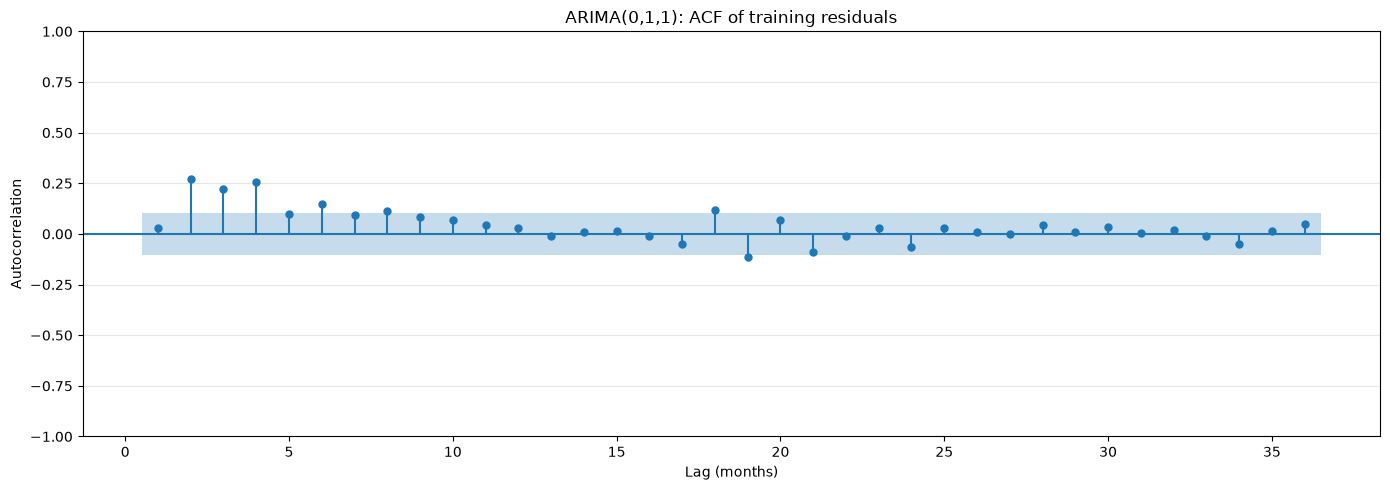

Ljung-Box test on training residuals (model_df=p+q=1):
              lb_stat   lb_pvalue  Reject H0 (5%)
Lag (months)                                     
3              44.294 2.40808e-10            True
6             79.0197 1.34551e-15            True
9             89.2724 6.53376e-16            True
12            92.0692 6.54706e-15            True
Evidence of remaining residual autocorrelation; compare other orders in exercise 3.


In [9]:
# TODO:
# 1. Natrénujte model ARIMA(0,1,1) na tréningových dátach.
# 2. Vykreslite ACF reziduí vybraného modelu.
# 3. Vykonajte Ljung-Box test na lagoch 3, 6, 9 a 12.

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

import matplotlib.pyplot as plt

# Fit only the chronological training sample from exercise 1.
# ARIMA applies d=1 internally; do not difference train again here.
arima011_model = ARIMA(train, order=(0, 1, 1), trend="n")
arima011_fit = arima011_model.fit()
if not arima011_fit.mle_retvals["converged"]:
    raise RuntimeError("ARIMA fitting did not converge; inspect the fit first.")
print("ARIMA(0,1,1) without drift: fitted training-sample parameters")
print(arima011_fit.params.to_string(float_format=lambda value: f"{value:.6g}"))
print(f"AIC: {arima011_fit.aic:.3f}; BIC: {arima011_fit.bic:.3f}")

# Exclude residuals affected by diffuse state initialization.
# The first residual of an integrated model can otherwise dominate the ACF.
arima011_burn = max(
    arima011_fit.loglikelihood_burn, arima011_fit.filter_results.nobs_diffuse
)
arima011_residuals = arima011_fit.resid.iloc[arima011_burn:].dropna()
print(f"Residuals used: {len(arima011_residuals)}; "
      f"initial observations excluded: {arima011_burn}")

fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(
    arima011_residuals, ax=ax, lags=36, alpha=0.05,
    bartlett_confint=False, zero=False,
    title="ARIMA(0,1,1): ACF of training residuals",
)
ax.set_xlabel("Lag (months)")
ax.set_ylabel("Autocorrelation")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# H0: residual autocorrelations at lags 1 through h are jointly zero.
# Account for p+q=1 fitted AR/MA coefficient; d is not included.
ljung_box_011 = acorr_ljungbox(
    arima011_residuals, lags=[3, 6, 9, 12], model_df=1, return_df=True
)
ljung_box_011.index.name = "Lag (months)"
ljung_box_011["Reject H0 (5%)"] = ljung_box_011["lb_pvalue"] < 0.05
print("Ljung-Box test on training residuals (model_df=p+q=1):")
print(ljung_box_011.to_string(float_format=lambda value: f"{value:.6g}"))
if ljung_box_011["Reject H0 (5%)"].any():
    print("Evidence of remaining residual autocorrelation; compare other orders in exercise 3.")
else:
    print("No significant joint residual autocorrelation detected at the tested horizons.")


### Exercise 2 — interpretation

- **ARIMA(0,1,1):** There are no AR terms (`p=0`), the model takes one ordinary difference internally (`d=1`), and the differenced series has one MA term (`q=1`). The MA term describes dependence on the previous innovation, not a rolling average of observed values. This baseline is fitted without drift and uses only the training data.
- **Residuals:** These are observed values minus their one-step predictions based on information available before each observation. Initialization-affected residuals are excluded from both diagnostics. For this fit, one observation is excluded, leaving 351 residuals.
- **Residual ACF:** Spikes at several short lags remain outside the approximate 95% reference band. In particular, lags 2, 3, and 4 show remaining positive dependence. Individual spikes can occur by chance, so use the joint Ljung-Box test as well.
- **Ljung-Box:** The row at lag 12 tests autocorrelations at lags 1 through 12 jointly; it does not test only lag 12. At all requested horizons (3, 6, 9, and 12), p-values are below 0.05, so the null of no residual autocorrelation is rejected. The degrees of freedom are adjusted by `p+q=1`.
- **Conclusion:** ARIMA(0,1,1) does not fully capture the training series' dependence. Compare other orders in exercise 3. Forecast accuracy must be assessed separately on future observations; the test sample has not been used here.
- A large Ljung-Box p-value would mean insufficient evidence of autocorrelation, not proof of independent, identically distributed or normal residuals. AIC and BIC are useful for comparing candidate models on the same data; their absolute values alone do not establish adequacy.


# 3. Hľadanie vhodnejšieho modelu
| Typ procesu | ACF graf | PACF graf | Voľba rádu |
| :--- | :--- | :--- | :--- |
| **AR($p$)** | Postupný pokles (tail off) | **Prudký pád po lagu $p$** (cut off) | $p$ = počet lagov pred pádom, $q = 0$ |
| **MA($q$)** | **Prudký pád po lagu $q$** (cut off) | Postupný pokles (tail off) | $p = 0$, $q$ = počet lagov pred pádom |
| **ARMA($p,q$)** | Postupný pokles | Postupný pokles | Kandidáti: kombinácie $p, q$ overené cez AIC/BIC |
| **Biely šum** | Všetky lagy v pásme šumu | Všetky lagy v pásme šumu | $p = 0, q = 0$ |

ADF comparison on training data:
   ADF statistic     p-value  ADF lags  Reject unit root (5%)
d                                                            
0       -1.65135    0.456338         4                  False
1       -4.51507 0.000184673         3                   True
Selected d=1 for the candidate search.


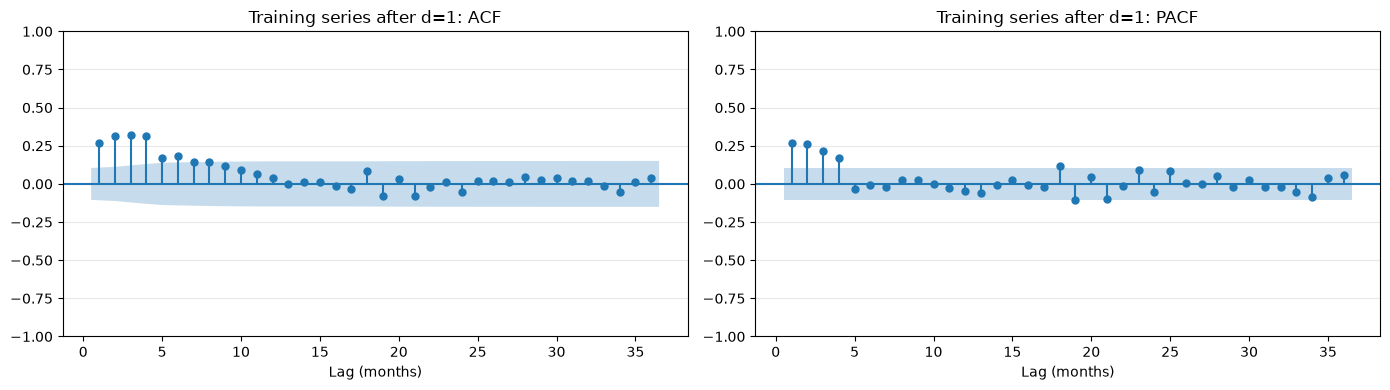

Candidate models (smaller AIC/BIC is better):
    Order     AIC     BIC  Usable  Warning count Status
(1, 1, 2) 489.549 504.992    True              0     ok
(1, 1, 3) 490.220 509.524    True              0     ok
(3, 1, 1) 490.540 509.844    True              0     ok
(2, 1, 2) 490.565 509.869    True              0     ok
(2, 1, 1) 490.786 506.229    True              1     ok
(3, 1, 2) 491.845 515.010    True              0     ok
(2, 1, 3) 492.218 515.383    True              0     ok
(3, 1, 3) 492.709 519.735    True              0     ok
(1, 1, 1) 493.976 505.559    True              1     ok
(3, 1, 0) 501.633 517.076    True              0     ok
(2, 1, 0) 519.766 531.349    True              0     ok
(0, 1, 3) 527.702 543.145    True              0     ok
(0, 1, 2) 543.734 555.316    True              0     ok
(1, 1, 0) 546.705 554.426    True              0     ok
(0, 1, 1) 557.766 565.487    True              0     ok
(0, 1, 0) 576.414 580.274    True              0     ok
Be

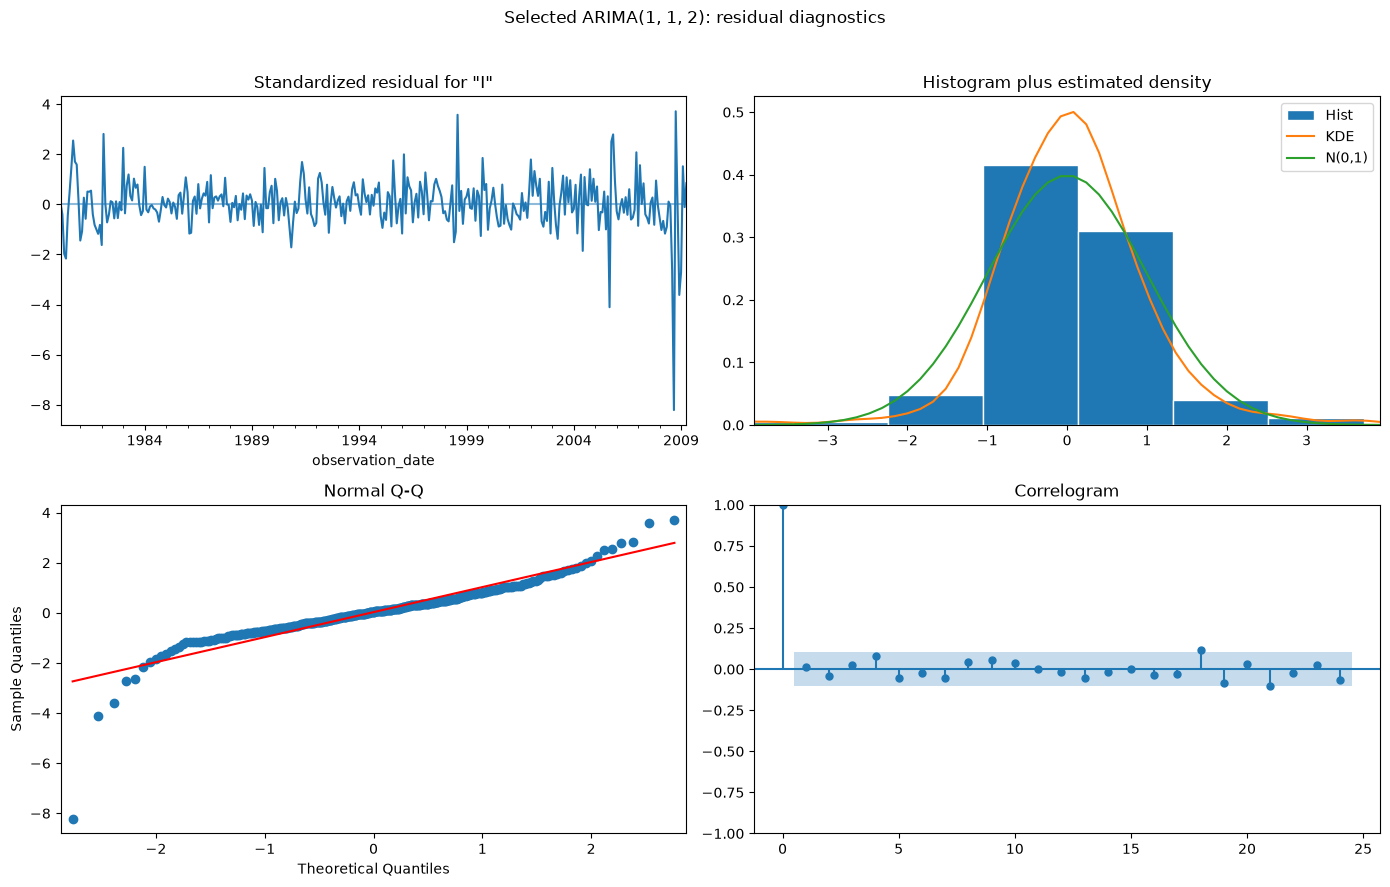

Ljung-Box for ARIMA(1, 1, 2), model_df=3:
              lb_stat  lb_pvalue  Reject H0 (5%)
Lag (months)                                    
12            7.74461   0.560075           False
24            23.5974   0.312969           False
No significant joint residual autocorrelation detected at the tested horizons.
Manual versus automatic model selection:
                      Order     AIC     BIC
Selection                                  
Manual grid: AIC  (1, 1, 2) 489.549 504.992
Manual grid: BIC  (1, 1, 2) 489.549 504.992
auto_arima: AIC   (1, 1, 2) 489.549 504.992
Same AIC-selected order: True
All selection and diagnostics used train only; test is reserved for exercise 4.


In [10]:
# TODO:
# 1. Otestujte stacionaritu pomocou ADF testu. Ak rad nie je stacionárny, diferencujte ho a test zopakujte. Počet diferencií určuje parameter d.
# 2. Vykreslite ACF a PACF na návrh parametrov q a p.
# 3. Cez mriežkové vyhľadávanie (grid search) vypíšte a porovnajte AIC a BIC kandidátov.
# 4. Skontrolujte ACF reziduí zvoleného modelu cez plot_diagnostics().
# 5. Vykonajte Ljungov–Boxov test.
# 6. Porovnajte výber vášho modelu s použitím auto_arima, ktoré automatický zvolí najlepší model.

from pmdarima import auto_arima

import warnings
from inspect import signature
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# 1. Select d using only training data, with a maximum of two differences.
adf_search_options = {"regression": "c", "autolag": "AIC"}
if "result_object" in signature(adfuller).parameters:
    adf_search_options["result_object"] = False
stationary_train = train.copy()
adf_search_rows = []
for differencing_order in range(3):
    statistic, p_value, used_lags, _, _, _ = adfuller(
        stationary_train.dropna(), **adf_search_options
    )
    adf_search_rows.append({
        "d": differencing_order, "ADF statistic": statistic,
        "p-value": p_value, "ADF lags": used_lags,
        "Reject unit root (5%)": p_value < 0.05,
    })
    if p_value < 0.05:
        selected_d = differencing_order
        break
    stationary_train = stationary_train.diff().dropna()
else:
    raise ValueError("ADF did not reject a unit root up to d=2; inspect the series.")

adf_search = pd.DataFrame(adf_search_rows).set_index("d")
print("ADF comparison on training data:")
print(adf_search.to_string(float_format=lambda value: f"{value:.6g}"))
print(f"Selected d={selected_d} for the candidate search.")

# 2. Use the transformed training series to suggest low-order AR/MA terms.
diagnostic_lags = min(36, len(stationary_train) // 2 - 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(stationary_train, ax=axes[0], lags=diagnostic_lags,
         zero=False, title=f"Training series after d={selected_d}: ACF")
plot_pacf(stationary_train, ax=axes[1], lags=diagnostic_lags,
          method="ywm", zero=False,
          title=f"Training series after d={selected_d}: PACF")
for ax in axes:
    ax.set_xlabel("Lag (months)")
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# 3. Compare all 16 nonseasonal models with p,q in 0..3, at the same d.
# Fit the original train series: ARIMA performs differencing internally.
# No drift/intercept in either search; use identical stationarity constraints.
max_p = max_q = 3
grid_rows, grid_models, grid_fit_messages = [], {}, {}
for p, q in product(range(max_p + 1), range(max_q + 1)):
    order = (p, selected_d, q)
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = ARIMA(
                train, order=order, trend="n",
                enforce_stationarity=True, enforce_invertibility=True,
            ).fit(method_kwargs={"maxiter": 200})
        grid_fit_messages[order] = [str(item.message) for item in caught]
        converged = fitted.mle_retvals.get("converged", False)
        finite = np.isfinite(fitted.aic) and np.isfinite(fitted.bic)
        valid = converged and finite
        grid_rows.append({
            "Order": order, "AIC": fitted.aic, "BIC": fitted.bic,
            "Usable": valid, "Warning count": len(caught),
            "Status": "ok" if valid else "not converged or nonfinite criteria",
        })
        if valid:
            grid_models[order] = fitted
    except (ValueError, np.linalg.LinAlgError) as error:
        grid_rows.append({
            "Order": order, "AIC": np.nan, "BIC": np.nan,
            "Usable": False, "Warning count": 0, "Status": str(error),
        })

grid_results = pd.DataFrame(grid_rows).sort_values("AIC", na_position="last")
print("Candidate models (smaller AIC/BIC is better):")
print(grid_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
usable_grid = grid_results.loc[grid_results["Usable"]]
if usable_grid.empty:
    raise RuntimeError("No candidate converged with finite AIC and BIC.")
best_order = usable_grid.loc[usable_grid["AIC"].idxmin(), "Order"]
best_bic_order = usable_grid.loc[usable_grid["BIC"].idxmin(), "Order"]
best_model = grid_models[best_order]
best_bic_model = grid_models[best_bic_order]
print("Best order by AIC:", best_order)
print("Best order by BIC:", best_bic_order)

# 4. Inspect standardized residuals, distribution, Q-Q plot and residual ACF.
diagnostic_figure = best_model.plot_diagnostics(lags=24, figsize=(14, 9))
diagnostic_figure.suptitle(f"Selected ARIMA{best_order}: residual diagnostics")
diagnostic_figure.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# 5. Joint residual autocorrelation tests, adjusting for the fitted p+q.
best_burn = max(best_model.loglikelihood_burn,
                best_model.filter_results.nobs_diffuse)
best_residuals = best_model.resid.iloc[best_burn:].dropna()
best_model_df = best_order[0] + best_order[2]
# Both horizons exceed p+q for every model in this grid.
best_ljung_box = acorr_ljungbox(
    best_residuals, lags=[12, 24], model_df=best_model_df, return_df=True
)
best_ljung_box.index.name = "Lag (months)"
best_ljung_box["Reject H0 (5%)"] = best_ljung_box["lb_pvalue"] < 0.05
print(f"Ljung-Box for ARIMA{best_order}, model_df={best_model_df}:")
print(best_ljung_box.to_string(float_format=lambda value: f"{value:.6g}"))
if best_ljung_box["Reject H0 (5%)"].any():
    print("Residual autocorrelation remains at one or more tested horizons.")
else:
    print("No significant joint residual autocorrelation detected at the tested horizons.")

# 6. Compare with auto_arima using the same d, grid, trend and AIC criterion.
# Exhaustive search avoids a different answer caused only by a stepwise path.
auto_model = auto_arima(
    train, d=selected_d, start_p=0, start_q=0, max_p=max_p, max_q=max_q,
    seasonal=False, m=1, max_order=None, stepwise=False, n_jobs=1,
    information_criterion="aic", with_intercept=False,
    method="lbfgs", maxiter=200, suppress_warnings=True,
    error_action="warn", trace=False,
    sarimax_kwargs={"enforce_stationarity": True, "enforce_invertibility": True},
)
if not auto_model.arima_res_.mle_retvals.get("converged", False):
    raise RuntimeError("The selected auto_arima fit did not converge.")
model_comparison = pd.DataFrame([
    {"Selection": "Manual grid: AIC", "Order": best_order,
     "AIC": best_model.aic, "BIC": best_model.bic},
    {"Selection": "Manual grid: BIC", "Order": best_bic_order,
     "AIC": best_bic_model.aic, "BIC": best_bic_model.bic},
    {"Selection": "auto_arima: AIC", "Order": auto_model.order,
     "AIC": auto_model.aic(), "BIC": auto_model.bic()},
]).set_index("Selection")
print("Manual versus automatic model selection:")
print(model_comparison.to_string(float_format=lambda value: f"{value:.3f}"))
print("Same AIC-selected order:", best_order == auto_model.order)
print("All selection and diagnostics used train only; test is reserved for exercise 4.")


### Exercise 3 — interpretation

1. **Differencing order:** ADF is run on the training levels and repeated after differencing. The first order that rejects a unit root at 5% becomes the candidate `d`. Rejection is evidence against a unit root, not proof of all stationarity properties. For these data, one ordinary difference is sufficient by this criterion.
2. **ACF and PACF:** Examine the differenced training series. ACF suggests MA terms and PACF suggests AR terms for simple pure processes; mixed processes generally show gradual decay in both. These plots suggest candidates rather than uniquely identifying an order.
3. **Grid search:** Compare all 16 models with `p,q` from 0 to 3, at the selected `d`. Smaller AIC/BIC is preferred within this candidate set. Only converged fits with finite criteria are eligible. Warnings are counted in the table and their texts are retained in `grid_fit_messages`.
4. **Selected model:** `best_order` and `best_model` use the lowest AIC; the BIC choice is reported separately. This is a bounded comparison without drift or seasonality, not a claim to have found the best possible forecasting model.
5. **Residual diagnostics:** `plot_diagnostics()` shows standardized residuals, their distribution, a normal Q-Q plot, and their ACF. Look for remaining patterns, changing variance and substantial departures from normality. Individual ACF spikes can occur by chance.
6. **Ljung-Box:** Test residual correlations jointly through lags 12 and 24, using degrees of freedom `h-(p+q)`. Small p-values indicate remaining dependence. Large p-values do not prove independent, identically distributed or normal errors.
7. **Automatic comparison:** `auto_arima` uses the same training data, fixed `d`, limits on `p,q`, no intercept/drift, nonseasonal specification and AIC objective. It searches the whole grid. Numerical optimization, initialization and admissibility checks can still cause differences between libraries. The selected order is not inferred from the test sample.

ARIMA receives the original training levels even though ACF/PACF use the differenced series. Passing the differenced series to an ARIMA model with nonzero `d` would difference twice. The test sample remains reserved for forecasting evaluation in exercise 4.

**Reference results for the supplied training sample:** ADF selects `d=1` (p-value about 0.000185 after differencing). Both AIC and BIC select ARIMA(1,1,2), with AIC about 489.549 and BIC about 504.992. `auto_arima` selects the same order. Ljung-Box p-values are about 0.560 at lag 12 and 0.313 at lag 24, so residual autocorrelation is not detected at those horizons. This improves the residual diagnostics of the ARIMA(0,1,1) baseline, but does not establish normality, constant variance or superior test-set forecast accuracy.


## 4. Evaluácia predikčnej schopnosti modelu pomocou Rolling-Origin

Rolling-Origin testuje ARIMA model opakovaným posúvaním (sliding) alebo rozširovaním (expanding) tréningového okna. 

<div align="center">
<img src="images/fixed-vs-rolling-window-time-series.png" alt="ACF vs PACF perspektíva" width="480"/>
</div>


Completed 12/88 rolling forecast origins.
Completed 24/88 rolling forecast origins.
Completed 36/88 rolling forecast origins.
Completed 48/88 rolling forecast origins.
Completed 60/88 rolling forecast origins.
Completed 72/88 rolling forecast origins.
Completed 84/88 rolling forecast origins.
Completed 88/88 rolling forecast origins.
One-month-ahead evaluation; sliding window=352 months.
                                  MAE     RMSE
Model                                         
Exp. smoothing (damped Holt) 0.351707 0.469447
ARIMA(1, 1, 2)               0.353536 0.474514
Naive                        0.405332 0.485901
Lowest MAE: Exp. smoothing (damped Holt)
Lowest RMSE: Exp. smoothing (damped Holt)


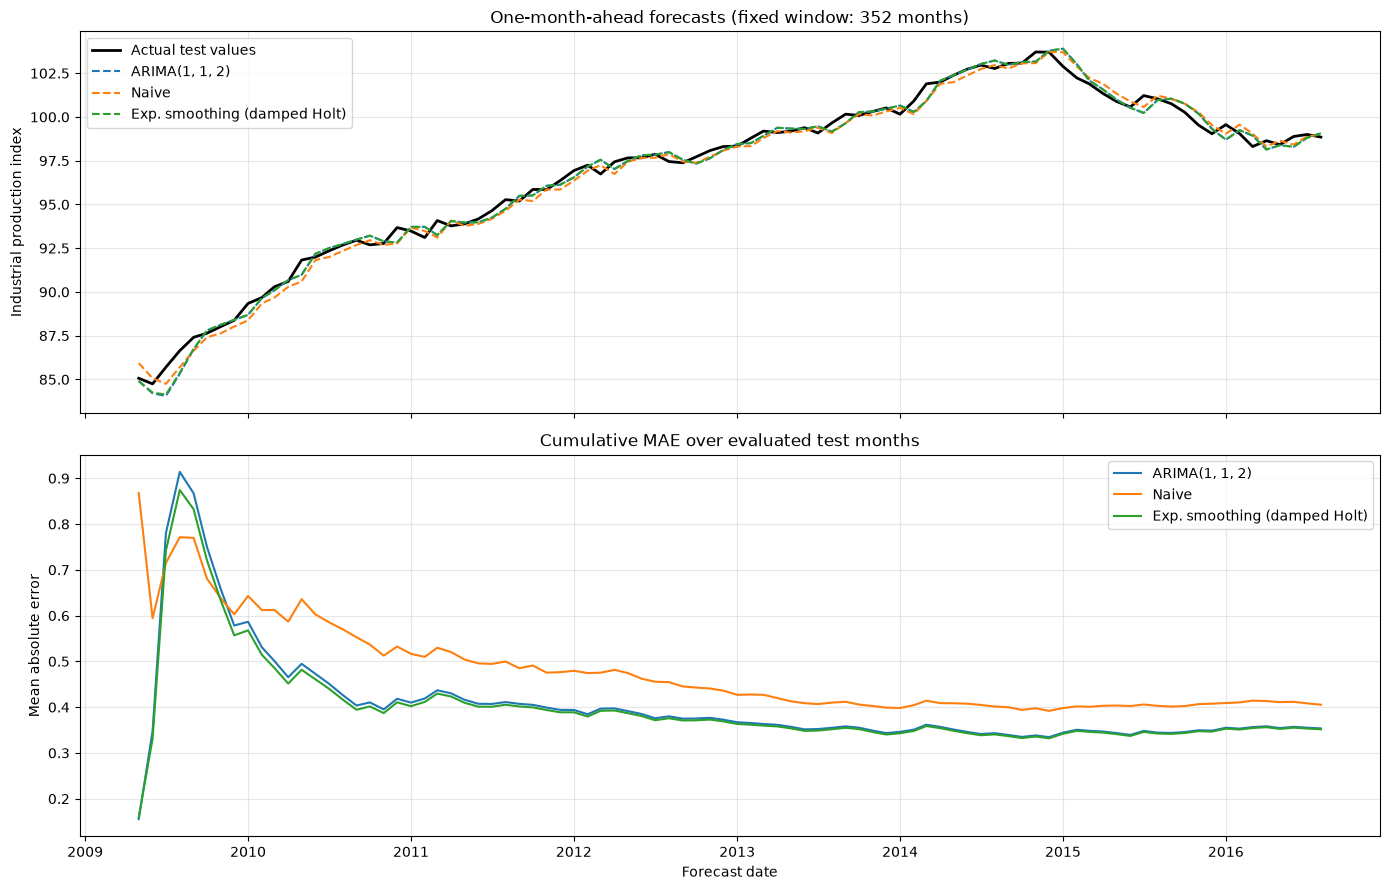

In [11]:
# TODO:
# 1. Evaluujte predikciu ARIMA modelu pomocou testovacích dát a posuvného okna.
# 2. Porovnajte výsledky ARIMA modelu s inými modelmi (Naive model, Exp Smoothing) pomocou MAE a RMSE
# 3. Vykreslite výsledky predikcií modelov na grafe

from statsmodels.tsa.holtwinters import ExponentialSmoothing

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Evaluate one-month-ahead forecasts with a fixed-length sliding window.
# Model structure and window length are fixed before evaluating test forecasts.
rolling_order = tuple(best_order)
window_size = len(train)
arima_label = f"ARIMA{rolling_order}"
smoothing_label = "Exp. smoothing (damped Holt)"
model_labels = [arima_label, "Naive", smoothing_label]
history = train.copy()
forecast_rows, origin_rows = [], []
rolling_fit_messages = {}

for step, (forecast_date, actual) in enumerate(test.items(), start=1):
    # At this origin, history contains only observations already revealed.
    window = history.iloc[-window_size:].asfreq("MS")
    if len(window) != window_size or window.isna().any():
        raise ValueError("The rolling window must contain consecutive monthly values.")
    if window.index.max() >= forecast_date:
        raise ValueError("The fitting window includes the forecast target or future data.")

    with warnings.catch_warnings(record=True) as arima_warnings:
        warnings.simplefilter("always")
        rolling_arima_fit = ARIMA(
            window, order=rolling_order, trend="n",
            enforce_stationarity=True, enforce_invertibility=True,
        ).fit(method_kwargs={"maxiter": 300})
    if not rolling_arima_fit.mle_retvals.get("converged", False):
        raise RuntimeError(f"ARIMA did not converge at {forecast_date:%Y-%m}.")
    arima_prediction = float(rolling_arima_fit.forecast(steps=1).iloc[0])

    # The naive one-step forecast is the most recent observed value.
    naive_prediction = float(window.iloc[-1])

    # Nonseasonal Holt smoothing with an additive, damped trend.
    # Re-estimate its parameters on the same window as ARIMA at every origin.
    with warnings.catch_warnings(record=True) as smoothing_warnings:
        warnings.simplefilter("always")
        rolling_smoothing_fit = ExponentialSmoothing(
            window, trend="add", damped_trend=True, seasonal=None,
            initialization_method="estimated",
        ).fit(optimized=True, use_brute=False, method="L-BFGS-B",
              minimize_kwargs={"options": {"maxiter": 500}})
    if not rolling_smoothing_fit.mle_retvals.get("success", False):
        raise RuntimeError(f"Exponential smoothing did not converge at {forecast_date:%Y-%m}.")
    smoothing_prediction = float(rolling_smoothing_fit.forecast(steps=1).iloc[0])

    forecast_rows.append({
        "Date": forecast_date, "Actual": float(actual),
        arima_label: arima_prediction, "Naive": naive_prediction,
        smoothing_label: smoothing_prediction,
    })
    origin_rows.append({
        "Forecast date": forecast_date, "Window start": window.index.min(),
        "Window end": window.index.max(), "Window size": len(window),
        "ARIMA converged": rolling_arima_fit.mle_retvals["converged"],
        "Smoothing converged": rolling_smoothing_fit.mle_retvals["success"],
    })
    rolling_fit_messages[forecast_date] = {
        "ARIMA": [str(item.message) for item in arima_warnings],
        "Smoothing": [str(item.message) for item in smoothing_warnings],
    }

    # Reveal the actual target only after all three forecasts have been made.
    # At the next origin, the oldest observation drops out of the fitting window.
    history.loc[forecast_date] = actual
    if step % 12 == 0 or step == len(test):
        print(f"Completed {step}/{len(test)} rolling forecast origins.")

rolling_predictions = pd.DataFrame(forecast_rows).set_index("Date")
rolling_origins = pd.DataFrame(origin_rows).set_index("Forecast date")
if not np.isfinite(rolling_predictions.to_numpy()).all():
    raise ValueError("Forecasts and actual values must be finite before scoring.")

# Score every model on exactly the same dates and the original INDPRO scale.
rolling_errors = rolling_predictions[model_labels].sub(
    rolling_predictions["Actual"], axis=0
)
rolling_scores = pd.DataFrame({
    "MAE": rolling_errors.abs().mean(),
    "RMSE": np.sqrt(rolling_errors.pow(2).mean()),
}).sort_values("RMSE")
rolling_scores.index.name = "Model"
print(f"One-month-ahead evaluation; sliding window={window_size} months.")
print(rolling_scores.to_string(float_format=lambda value: f"{value:.6f}"))
print("Lowest MAE:", rolling_scores["MAE"].idxmin())
print("Lowest RMSE:", rolling_scores["RMSE"].idxmin())

# Compare forecasts and how average absolute errors develop over test months.
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(rolling_predictions.index, rolling_predictions["Actual"],
             color="black", linewidth=2, label="Actual test values")
colors = ["tab:blue", "tab:orange", "tab:green"]
cumulative_mae = rolling_errors.abs().expanding().mean()
for label, color in zip(model_labels, colors):
    axes[0].plot(rolling_predictions.index, rolling_predictions[label],
                 color=color, linestyle="--", label=label)
    axes[1].plot(cumulative_mae.index, cumulative_mae[label],
                 color=color, label=label)
axes[0].set_title(f"One-month-ahead forecasts (fixed window: {window_size} months)")
axes[0].set_ylabel("Industrial production index")
axes[1].set_title("Cumulative MAE over evaluated test months")
axes[1].set_ylabel("Mean absolute error")
axes[1].set_xlabel("Forecast date")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Exercise 4 — interpretation

- **Rolling origin:** Produce a forecast for the next month, observe its actual value, move the origin forward by one month, and refit. The fixed window contains the most recent 352 observations at every origin. New observed months enter the window and the oldest months leave it.
- **Fair comparison:** ARIMA, Naive and exponential smoothing receive the same information and predict the same 88 target months. ARIMA's order is taken from exercise 3 and is not selected again using test scores. The smoothing specification is fixed as nonseasonal Holt smoothing with an additive damped trend.
- **Naive forecast:** The prediction for next month equals the most recently observed value. This is an important baseline: a more complicated model does not automatically forecast better.
- **MAE:** The mean absolute forecast error, in industrial-production index points. Every error contributes in proportion to its absolute size.
- **RMSE:** The square root of the mean squared error, also in index points. Large forecast errors receive greater weight. Smaller MAE and RMSE are preferred; they can rank models differently.
- **Plots:** The first panel compares actual values and one-step predictions. The second shows the mean absolute error accumulated up to each evaluation date; its final values equal the MAE column in the score table.
- **Information timing:** A target observation is added to the history only after its forecasts have been recorded. Earlier test observations can legitimately be used at later origins once they are observed. `rolling_origins` records the window dates and convergence checks; warning texts are retained in `rolling_fit_messages`.
- This evaluates repeated one-month-ahead forecasts with monthly refitting, not a single 88-month forecast from the original training endpoint. The comparison describes this test period and does not prove universal superiority. If the results are used to tune model settings, a further untouched evaluation period is needed.

Reference results for the supplied data, 352-month windows and 88 one-step forecasts:

| Model | MAE | RMSE |
| --- | ---: | ---: |
| Exponential smoothing (damped Holt) | 0.351707 | 0.469447 |
| ARIMA(1,1,2) | 0.353536 | 0.474514 |
| Naive | 0.405332 | 0.485901 |

Damped Holt has slightly smaller MAE and RMSE than ARIMA on this evaluation period. Both improve on Naive by these metrics. The small difference between Holt and ARIMA is descriptive; no statistical significance claim is made.


### BONUS - 2B

Spracujte dvojročné dáta nemeckej elektrickej siete z priečinka data/ a vytvorte model na predikciu dennej celkovej výroby elektriny pre jun-dec 2025. Porovnajte presnosť modelu SARIMA s modelom SARIMAX rozšíreným o 2 vhodné exogénne premenné. Odôvodnite svoj výber exogénnych premenných.

### Energy bonus — data preparation

Aggregate daily generation and prepare a fixed training/test split, preserving the original bonus assignment above.


In [12]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Load both quarter-hour datasets, handling their different header positions.
energy_data_dir = Path("data")
if not (energy_data_dir / "energy-charts_Public_net_electricity_generation_in_Germany_in_2024.csv").is_file():
    energy_data_dir = Path("02_exercises/data")


def load_energy_year(year):
    file = energy_data_dir / f"energy-charts_Public_net_electricity_generation_in_Germany_in_{year}.csv"
    with file.open(encoding="utf-8-sig") as handle:
        for header_row, line in enumerate(handle):
            if line.startswith("Date "):
                break
        else:
            raise ValueError(f"No date header found in {file.name}.")
    raw = pd.read_csv(file, skiprows=header_row, dtype=str)
    dates = pd.to_datetime(raw.iloc[:, 0], errors="coerce", utc=True)
    if (dates.isna() & raw.iloc[:, 0].notna()).any():
        raise ValueError(f"Invalid timestamps in {file.name}.")
    # The units row has no date; remove it before converting values to numbers.
    values = raw.loc[dates.notna()].iloc[:, 1:].apply(pd.to_numeric, errors="raise")
    values.index = pd.DatetimeIndex(dates.loc[dates.notna()]).tz_convert("Europe/Berlin")
    return values


energy_intervals = pd.concat([load_energy_year(2024), load_energy_year(2025)]).sort_index()
if not energy_intervals.index.is_unique or energy_intervals.isna().any().any():
    raise ValueError("Check duplicate timestamps or missing interval values.")
if not energy_intervals.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=15)).all():
    raise ValueError("The input must contain consecutive 15-minute intervals.")

# Sum generation sources, excluding consumption, demand, percentages and prices.
generation_columns = [
    "Hydro Run-of-River", "Biomass", "Fossil brown coal / lignite",
    "Fossil hard coal", "Fossil oil", "Fossil coal-derived gas", "Fossil gas",
    "Geothermal", "Hydro water reservoir", "Hydro pumped storage", "Others",
    "Waste", "Wind offshore", "Wind onshore", "Solar",
]
# MW * 0.25 hours = MWh; divide by 1000 to obtain GWh.
interval_generation_gwh = energy_intervals[generation_columns].sum(axis=1) * 0.25 / 1000
energy_daily = pd.DataFrame({
    "Generation_GWh": interval_generation_gwh.resample("D").sum(min_count=1),
    "Load_GWh": (energy_intervals["Load"] * 0.25 / 1000).resample("D").sum(min_count=1),
    "Price_EUR_MWh": energy_intervals["Day Ahead Auction (DE-LU)"].resample("D").mean(),
})
# Aggregate in German local time first, then use timezone-free calendar-day labels.
energy_day_counts = energy_intervals.resample("D").size()
day_edges = pd.date_range("2024-01-01", "2026-01-01", freq="D", tz="Europe/Berlin")
expected_day_counts = np.asarray(
    (day_edges[1:].tz_convert("UTC") - day_edges[:-1].tz_convert("UTC"))
    / pd.Timedelta(minutes=15), dtype=int
)
if not np.array_equal(energy_day_counts.to_numpy(), expected_day_counts):
    raise ValueError("Incomplete local days or unexpected interval counts.")
energy_daily.index = energy_daily.index.tz_localize(None)
energy_daily = energy_daily.asfreq("D")
expected_daily_index = pd.date_range("2024-01-01", "2025-12-31", freq="D")
if not energy_daily.index.equals(expected_daily_index) or energy_daily.isna().any().any():
    raise ValueError("Expected complete daily coverage for 2024 and 2025.")

# Fixed forecast origin: all training data end on May 31, 2025.
energy_train = energy_daily.loc[:"2025-05-31"].copy()
energy_test = energy_daily.loc["2025-06-01":"2025-12-31"].copy()
energy_exog_columns = ["Load_GWh", "Price_EUR_MWh"]
energy_target = "Generation_GWh"
print("Quarter-hour observations:", len(energy_intervals))
print("Daily interval counts:", energy_day_counts.value_counts().sort_index().to_dict())
print("Generation sources summed:", len(generation_columns))
print(f"Training: {len(energy_train)} days, {energy_train.index.min():%Y-%m-%d} to {energy_train.index.max():%Y-%m-%d}")
print(f"Testing: {len(energy_test)} days, {energy_test.index.min():%Y-%m-%d} to {energy_test.index.max():%Y-%m-%d}")


Quarter-hour observations: 70176
Daily interval counts: {92: 2, 96: 727, 100: 2}
Generation sources summed: 15
Training: 517 days, 2024-01-01 to 2025-05-31
Testing: 214 days, 2025-06-01 to 2025-12-31


### Energy bonus — SARIMA versus SARIMAX

Fit the two generation models, forecast the two external variables from training data, and evaluate the June-December forecasts.


Fitted: SARIMA generation
Fitted: SARIMAX generation
Fitted: Auxiliary Load_GWh
Fitted: Auxiliary Price_EUR_MWh
                         Training observations Last training date  Converged
Fit                                                                         
SARIMA generation                          517         2025-05-31       True
SARIMAX generation                         517         2025-05-31       True
Auxiliary Load_GWh                         517         2025-05-31       True
Auxiliary Price_EUR_MWh                    517         2025-05-31       True
SARIMAX standardized regressor coefficients (association, not causation):
Load_GWh         0.824316
Price_EUR_MWh   -0.545513
Fixed-origin forecasts for June-December 2025:
         MAE (GWh/day)  RMSE (GWh/day)
Model                                 
SARIMA         124.812         151.004
SARIMAX        224.150         285.999
Lowest MAE: SARIMA
Lowest RMSE: SARIMA
Auxiliary regressor forecast accuracy (evaluated after for

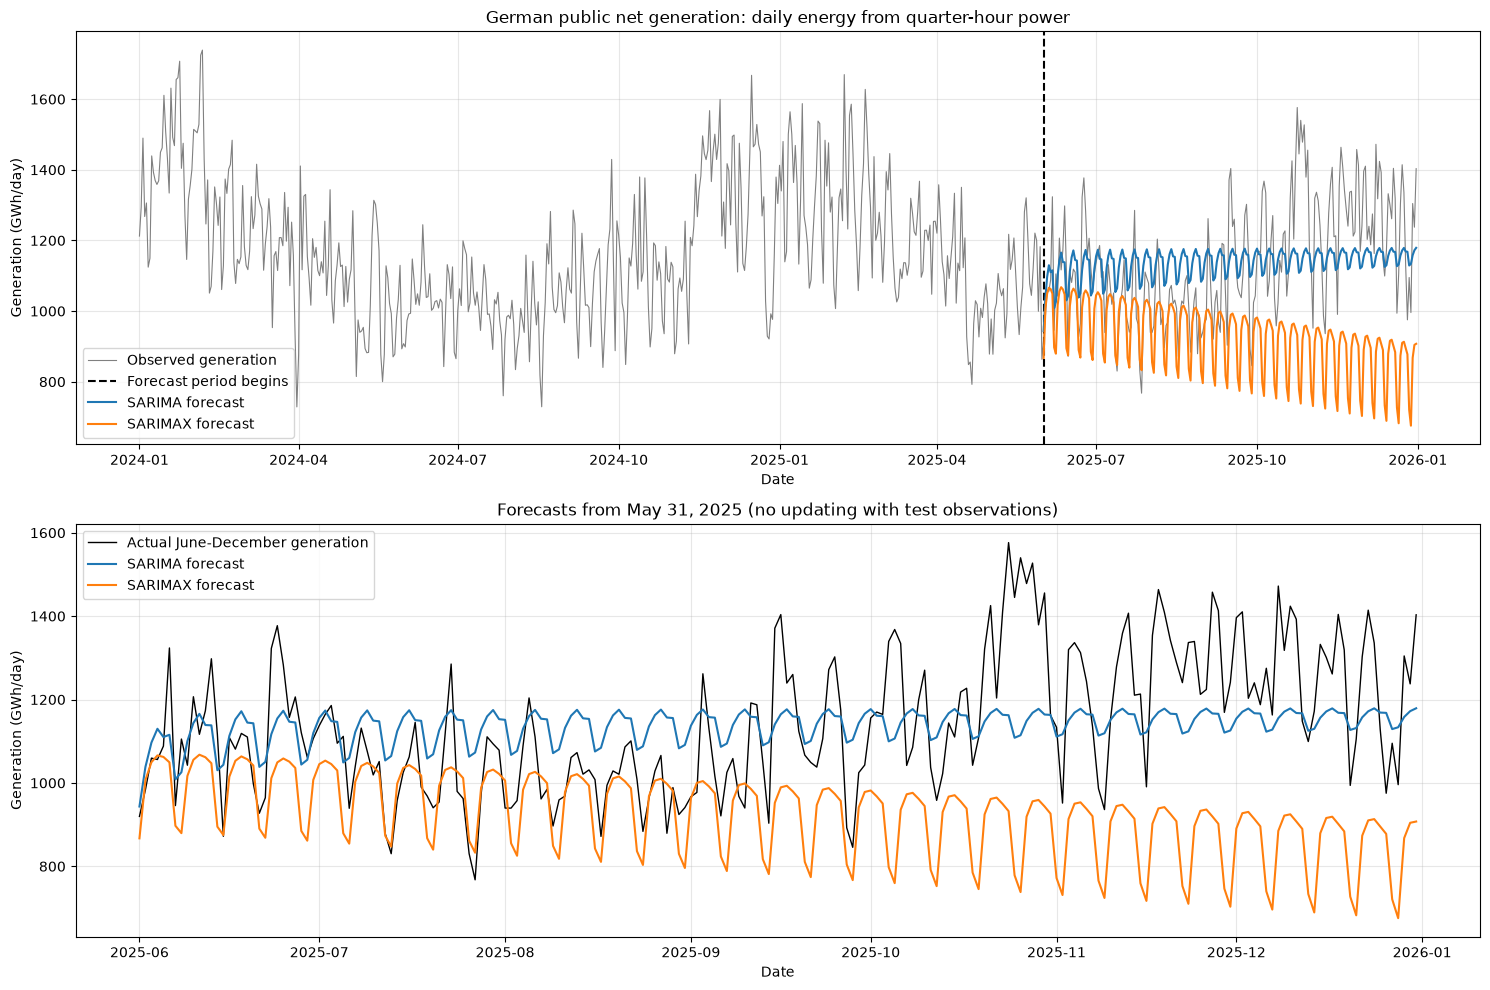

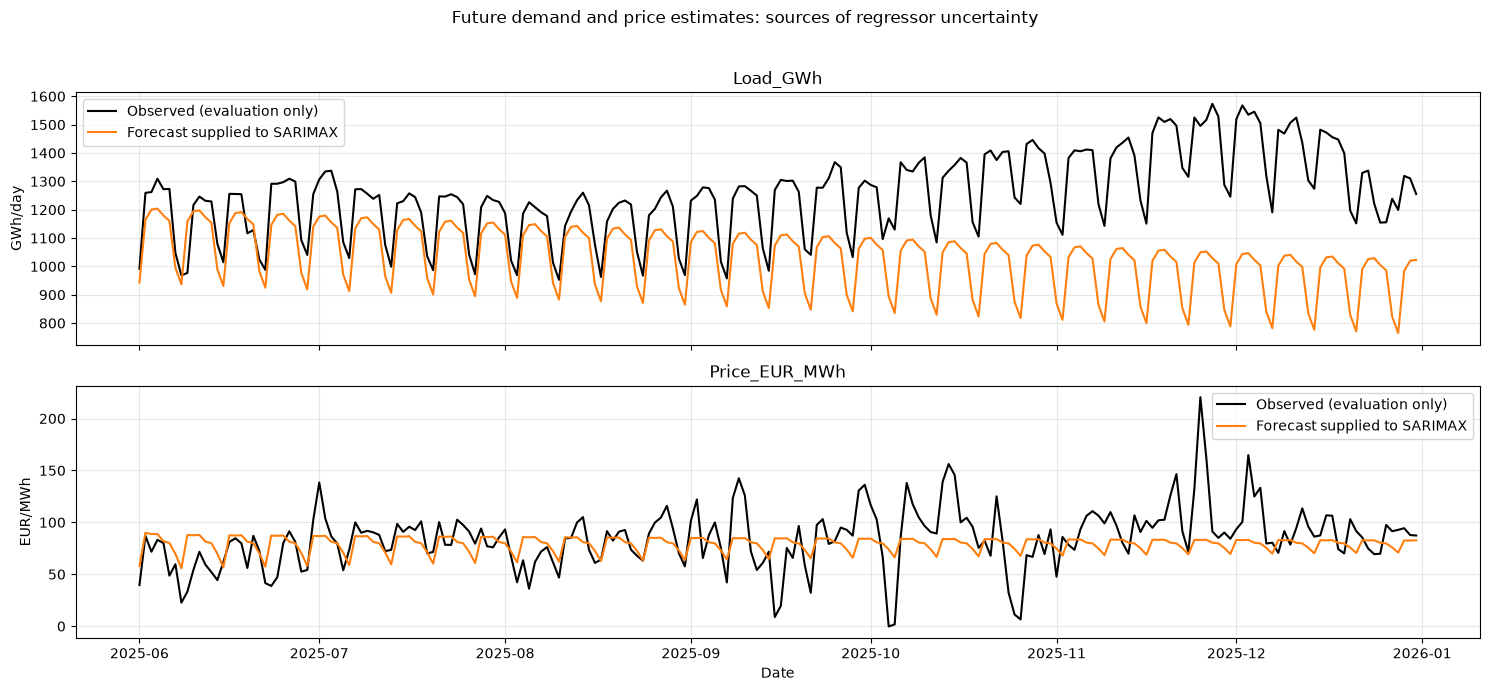

In [13]:
# 2. Use the same prespecified seasonal structure for both target models.
# Weekly seasonality for daily data: s=7. No test-set order tuning is performed.
energy_order = (1, 0, 1)
energy_seasonal_order = (1, 0, 1, 7)
energy_train_means = energy_train.mean()
energy_train_stds = energy_train.std()
if (energy_train_stds <= 0).any():
    raise ValueError("Training columns must have positive standard deviations.")
# Scale using training statistics only to improve numerical optimization.
energy_train_scaled = (energy_train - energy_train_means) / energy_train_stds
energy_fit_rows, energy_fit_messages = [], {}


def fit_energy_sarima(endog, label, exog=None):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = SARIMAX(
            endog, exog=exog, order=energy_order,
            seasonal_order=energy_seasonal_order, trend="c",
            enforce_stationarity=True, enforce_invertibility=True,
        ).fit(disp=False, maxiter=500)
    energy_fit_messages[label] = [str(item.message) for item in caught]
    converged = result.mle_retvals.get("converged", False)
    energy_fit_rows.append({
        "Fit": label, "Training observations": result.nobs,
        "Last training date": endog.index.max(), "Converged": converged,
    })
    if not converged or not np.isfinite(result.params).all():
        raise RuntimeError(f"The {label} fit did not converge with finite parameters.")
    print("Fitted:", label)
    return result


energy_sarima = fit_energy_sarima(energy_train_scaled[energy_target], "SARIMA generation")
energy_sarimax = fit_energy_sarima(
    energy_train_scaled[energy_target], "SARIMAX generation",
    exog=energy_train_scaled[energy_exog_columns],
)

# 3. Future observed demand and prices are unavailable at the forecast origin.
# Forecast both regressors using auxiliary models trained before June 2025.
energy_aux_models = {}
energy_future_exog_scaled = pd.DataFrame(index=energy_test.index)
for column in energy_exog_columns:
    auxiliary = fit_energy_sarima(energy_train_scaled[column], f"Auxiliary {column}")
    energy_aux_models[column] = auxiliary
    energy_future_exog_scaled[column] = auxiliary.forecast(steps=len(energy_test))
if not np.isfinite(energy_future_exog_scaled.to_numpy()).all():
    raise ValueError("The forecast regressor values must be finite.")

energy_sarima_prediction_scaled = energy_sarima.forecast(steps=len(energy_test))
energy_sarimax_prediction_scaled = energy_sarimax.forecast(
    steps=len(energy_test), exog=energy_future_exog_scaled
)
energy_predictions = pd.DataFrame({
    "SARIMA": energy_sarima_prediction_scaled * energy_train_stds[energy_target] + energy_train_means[energy_target],
    "SARIMAX": energy_sarimax_prediction_scaled * energy_train_stds[energy_target] + energy_train_means[energy_target],
}, index=energy_test.index)
energy_future_exog = (
    energy_future_exog_scaled * energy_train_stds[energy_exog_columns]
    + energy_train_means[energy_exog_columns]
)
energy_fit_audit = pd.DataFrame(energy_fit_rows).set_index("Fit")
print(energy_fit_audit.to_string())
print("SARIMAX standardized regressor coefficients (association, not causation):")
print(energy_sarimax.params[energy_exog_columns].to_string())

# 4. Use June-December observations only now, for scoring and plots.
energy_actual = energy_test[energy_target]
if not np.isfinite(energy_predictions.to_numpy()).all():
    raise ValueError("All generation forecasts must be finite.")
energy_errors = energy_predictions.sub(energy_actual, axis=0)
energy_scores = pd.DataFrame({
    "MAE (GWh/day)": energy_errors.abs().mean(),
    "RMSE (GWh/day)": np.sqrt(energy_errors.pow(2).mean()),
}).sort_values("RMSE (GWh/day)")
energy_scores.index.name = "Model"
print("Fixed-origin forecasts for June-December 2025:")
print(energy_scores.to_string(float_format=lambda value: f"{value:.3f}"))
print("Lowest MAE:", energy_scores["MAE (GWh/day)"].idxmin())
print("Lowest RMSE:", energy_scores["RMSE (GWh/day)"].idxmin())

# Check auxiliary forecast errors separately; their values have different units.
energy_exog_errors = energy_future_exog - energy_test[energy_exog_columns]
energy_exog_scores = pd.DataFrame({
    "MAE": energy_exog_errors.abs().mean(),
    "RMSE": np.sqrt(energy_exog_errors.pow(2).mean()),
    "Units": ["GWh/day", "EUR/MWh"],
})
print("Auxiliary regressor forecast accuracy (evaluated after forecasting):")
print(energy_exog_scores.to_string(float_format=lambda value: f"{value:.3f}"))

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
axes[0].plot(energy_daily.index, energy_daily[energy_target],
             color="gray", linewidth=0.8, label="Observed generation")
axes[0].axvline(pd.Timestamp("2025-06-01"), color="black", linestyle="--",
               label="Forecast period begins")
axes[0].set_title("German public net generation: daily energy from quarter-hour power")
axes[0].set_ylabel("Generation (GWh/day)")
axes[1].plot(energy_actual.index, energy_actual, color="black",
             linewidth=1, label="Actual June-December generation")
for name, color in (("SARIMA", "tab:blue"), ("SARIMAX", "tab:orange")):
    axes[0].plot(energy_predictions.index, energy_predictions[name],
                 color=color, label=f"{name} forecast")
    axes[1].plot(energy_predictions.index, energy_predictions[name],
                 color=color, label=f"{name} forecast")
axes[1].set_title("Forecasts from May 31, 2025 (no updating with test observations)")
axes[1].set_ylabel("Generation (GWh/day)")
for ax in axes:
    ax.set_xlabel("Date")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, column, units in zip(axes, energy_exog_columns, ["GWh/day", "EUR/MWh"]):
    ax.plot(energy_test.index, energy_test[column], color="black", label="Observed (evaluation only)")
    ax.plot(energy_future_exog.index, energy_future_exog[column],
            color="tab:orange", label="Forecast supplied to SARIMAX")
    ax.set_title(column)
    ax.set_ylabel(units)
    ax.grid(alpha=0.3)
    ax.legend()
axes[-1].set_xlabel("Date")
fig.suptitle("Future demand and price estimates: sources of regressor uncertainty")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


### Energy bonus — interpretation

**Data preparation.** The CSVs contain 15-minute mean power in MW, not daily energy. Multiply by 0.25 hours and sum to obtain MWh, then divide by 1000 for GWh. Sum the 15 generation-source columns. Exclude pumping consumption, load, the renewable percentage and price from the generation total. This target describes the public net generation covered by the supplied files, not a broader national gross-generation measure.

The timestamps contain both UTC+1 and UTC+2 offsets. Parse them in UTC and aggregate in `Europe/Berlin` local time. The two years include two 23-hour and two 25-hour days, containing 92 and 100 quarter-hour readings; the remaining days contain 96. The first file also has a preliminary note, and both files have a units row. No missing interval values are filled or silently discarded.

**Training and evaluation.** Train on January 1, 2024 through May 31, 2025 (517 days), and forecast June 1 through December 31, 2025 (214 days) from that single endpoint. Both target models use `(1,0,1)(1,0,1,7)` with a constant: a low-order model with a weekly seasonal period for daily observations. The orders are prespecified and are not tuned on the test period. This simple structure does not explicitly model annual seasonality.

**Why these two regressors?**

- `Load_GWh`: Daily electricity demand is a plausible predictor of generation required by the grid. Imports, exports and storage mean load is not identical to domestic generation.
- `Price_EUR_MWh`: The daily mean day-ahead price reflects market conditions associated with supply and demand. Negative prices are valid observations and are retained. Price is not a component of the target total. Its regression coefficient describes association, not a causal effect; contemporaneous price and generation can influence each other.

The supplied 2024 file notes a technical exchange issue on June 26. Prices are retained as supplied, so such observations can affect the fitted price relationship; no correction is invented.

**Future regressor availability.** Neither realized daily demand nor a full seven-month sequence of realized day-ahead prices is known on May 31. Two auxiliary weekly SARIMA models therefore forecast the regressors using training observations only. Their forecasts, not the observed June-December columns, are passed to SARIMAX. Scaling means and standard deviations are also calculated from training data only. Using actual future regressors would be a different, conditional evaluation and should not be described as a genuine May-end forecast.

**Comparison.** MAE and RMSE are evaluated on the same 214 days in GWh/day. For the supplied data and this fixed specification:

| Model | MAE (GWh/day) | RMSE (GWh/day) |
| --- | ---: | ---: |
| SARIMA | 124.812 | 151.004 |
| SARIMAX with forecast regressors | 224.150 | 285.999 |

SARIMA performs better on this evaluation period. Adding these predictors did not improve the forecast pipeline. Forecast errors in demand and price are one possible contributor, alongside model misspecification and changing relationships; the comparison does not isolate a single cause. The auxiliary accuracy table and plots show how estimated regressors differ from their subsequent realizations. Do not infer that SARIMAX is always worse, or that a better in-sample fit guarantees better forecasts.

This bonus is independent of the INDPRO exercises. It does not use their `train`, `test` or `best_order` variables. Unlike exercise 4's repeated one-step evaluation, it produces an entire 214-day forecast without incorporating newly observed generation during that period.
